<a href="https://colab.research.google.com/github/Dalalmachehoul1/Visualisation_Diabete/blob/main/TP_visualisation_diabete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# On importe les bibliothèques nécessaires
import pandas as pd          # pour manipuler les tableaux de données
import numpy as np           # pour les calculs numériques
import matplotlib.pyplot as plt  # pour les graphiques classiques
import seaborn as sns        # pour les graphiques statistiques plus jolis

# Pour afficher les graphiques directement dans le notebook
%matplotlib inline
# Ces 4 bibliothèques sont les plus utilisées en analyse de données. On les importe une seule fois au début.

In [4]:
# PARTIE 1 : Chargement et exploration
# Question 1 – Charger le fichier
# On charge le fichier CSV dans un DataFrame appelé df_brut
# Upload directement avec du code
from google.colab import files
uploaded = files.upload()

Saving diabetes_brut.csv to diabetes_brut.csv


In [5]:
# Ensuite charge le fichier
df_brut = pd.read_csv("diabetes_brut.csv")

In [8]:
# Après l’upload, tu peux vérifier que le fichier est bien
import os
print(os.listdir())
print("Fichier chargé avec succès !")
print("Dimensions du tableau :", df_brut.shape)
# pd.read_csv() lit le fichier et le transforme en tableau (DataFrame).
# On l’appelle df_brut car il contient encore les erreurs (doublons, valeurs manquantes…).

['.config', 'diabetes_brut.csv', 'sample_data']
Fichier chargé avec succès !
Dimensions du tableau : (450, 12)


In [9]:
# Question 2 – Premières explorations
print("--- 5 premières lignes ---")
display(df_brut.head())

print("\n--- 3 dernières lignes ---")
display(df_brut.tail(3))

print("\n--- Dimensions (lignes, colonnes) ---")
print(df_brut.shape)

print("\n--- Noms des colonnes ---")
print(df_brut.columns.tolist())

print("\n--- Type de chaque colonne ---")
print(df_brut.dtypes)

--- 5 premières lignes ---


,id,age,sexe,imc,pa,ct,ldl,hdl,ct_hdl,ltg,glu,progression
0,1,59,2,32.1,101,157,93.2,38.0,4.0,4.8598,87.0,151
1,2,48,1,21.6,87,183,103.2,70.0,3.0,3.8918,69.0,75
2,3,72,2,30.5,93,156,93.6,41.0,4.0,4.6728,85.0,141
3,4,24,1,25.3,84,198,131.4,40.0,5.0,4.8903,89.0,206
4,5,50,1,23.0,101,192,125.4,52.0,4.0,4.2905,80.0,135



--- 3 dernières lignes ---


,id,age,sexe,imc,pa,ct,ldl,hdl,ct_hdl,ltg,glu,progression
447,440,60,2,24.9,99.67,162,106.6,43.0,3.77,4.1271,95.0,132
448,441,36,1,30.0,95,201,125.2,42.0,4.79,5.1299,85.0,220
449,442,36,1,19.6,71,250,133.2,97.0,3.00,4.5951,92.0,57



--- Dimensions (lignes, colonnes) ---
(450, 12)

--- Noms des colonnes ---
['id', 'age', 'sexe', 'imc', 'pa', 'ct', 'ldl', 'hdl', 'ct_hdl', 'ltg', 'glu', 'progression']

--- Type de chaque colonne ---
id               int64
age              int64
sexe             int64
imc            float64
pa              object
ct               int64
ldl            float64
hdl            float64
ct_hdl         float64
ltg            float64
glu            float64
progression      int64
dtype: object


In [10]:
# Question 3 – Structure du tableau
print(df_brut.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           450 non-null    int64  
 1   age          450 non-null    int64  
 2   sexe         450 non-null    int64  
 3   imc          438 non-null    float64
 4   pa           450 non-null    object 
 5   ct           450 non-null    int64  
 6   ldl          450 non-null    float64
 7   hdl          450 non-null    float64
 8   ct_hdl       450 non-null    float64
 9   ltg          450 non-null    float64
 10  glu          441 non-null    float64
 11  progression  450 non-null    int64  
dtypes: float64(6), int64(5), object(1)
memory usage: 42.3+ KB
None


In [11]:
# Question 4 – Statistiques descriptives
# On arrondit à 1 décimale pour plus de lisibilité
display(df_brut.describe().round(1))

,id,age,sexe,imc,ct,ldl,hdl,ct_hdl,ltg,glu,progression
count,450.0,450.0,450.0,438.0,450.0,450.0,450.0,450.0,450.0,441.0,450.0
mean,222.2,54.9,1.5,26.4,189.4,115.7,49.7,4.1,4.6,91.2,152.4
std,127.9,78.5,0.5,4.3,34.6,30.4,12.9,1.3,0.5,11.6,77.5
min,1.0,19.0,1.0,18.0,97.0,41.6,22.0,2.0,3.3,58.0,25.0
25%,112.2,39.0,1.0,23.3,165.0,96.3,40.0,3.0,4.3,83.0,87.0
50%,221.5,50.0,1.0,25.8,186.0,113.0,48.0,4.0,4.6,91.0,140.5
75%,332.8,59.0,2.0,29.3,210.8,135.2,57.8,5.0,5.0,98.0,213.5
max,442.0,999.0,2.0,41.3,301.0,242.4,99.0,9.1,6.1,124.0,346.0


In [12]:
# Question 5 – Valeurs manquantes et doublons
print(" Nombre de valeurs manquantes par colonne ")
print(df_brut.isnull().sum())

print("\n Nombre de lignes en double (toutes les colonnes) ")
print(df_brut.duplicated().sum())

print("\n Nombre de doublons sur la colonne id seule ")
print(df_brut.duplicated(subset=["id"]).sum())

 Nombre de valeurs manquantes par colonne 
id              0
age             0
sexe            0
imc            12
pa              0
ct              0
ldl             0
hdl             0
ct_hdl          0
ltg             0
glu             9
progression     0
dtype: int64

 Nombre de lignes en double (toutes les colonnes) 
8

 Nombre de doublons sur la colonne id seule 
8


In [16]:
# PARTIE 2 : Nettoyage des données
# Question 6 – Traitement des doublons
# a) Afficher toutes les lignes concernées par un doublon
masque = df_brut.duplicated()
print("Lignes en double :")
display(df_brut.loc[masque, ["id", "age", "sexe", "imc", "progression"]].sort_values("id"))

# b) Supprimer les doublons et créer un nouveau DataFrame appelé df
print("\nDimensions AVANT suppression :", df_brut.shape)
df = df_brut.drop_duplicates().copy()
print("Dimensions APRÈS  suppression :", df.shape)

Lignes en double :


,id,age,sexe,imc,progression
93,93,43,1,26.8,48
133,132,22,1,19.9,158
144,142,41,1,30.8,317
194,191,51,1,25.2,292
296,292,69,1,28.1,248
395,390,47,2,26.5,51
421,415,71,2,27.0,131
432,425,49,2,27.4,111



Dimensions AVANT suppression : (450, 12)
Dimensions APRÈS  suppression : (442, 12)


In [17]:
# Question 7 – Convertir la colonne pa en nombres
# errors="coerce" transforme les valeurs impossibles ("n.d.") en NaN
df["pa"] = pd.to_numeric(df["pa"], errors="coerce")

print("Nombre de valeurs non convertibles (devenues NaN) :", df["pa"].isna().sum())

Nombre de valeurs non convertibles (devenues NaN) : 6


In [18]:
# Question 8 – Âges impossibles (> 120 ans)
# Détecter les patients concernés
masque_age = df["age"] > 120
print("Patients avec un âge impossible :")
display(df.loc[masque_age, ["id", "age", "imc"]])

# Remplacer ces âges par NaN
df.loc[masque_age, "age"] = np.nan
print("\nCes 3 âges ont été remplacés par NaN.")

Patients avec un âge impossible :


,id,age,imc
72,73,999,26.0
86,87,999,19.4
162,160,999,30.4



Ces 3 âges ont été remplacés par NaN.


In [19]:
# Question 9 – Supprimer les patients sans âge ou sans IMC
print("Nombre de lignes AVANT :", len(df))
df = df.dropna(subset=["age", "imc"]).copy()
print("Nombre de lignes APRÈS  :", len(df))

Nombre de lignes AVANT : 442
Nombre de lignes APRÈS  : 427


In [21]:
# Question 10 – Remplacer les NaN de pa par la médiane
mediane_pa = df["pa"].median()
print("Médiane de la pression artérielle :", mediane_pa)

df["pa"] = df["pa"].fillna(mediane_pa)
print("Valeurs manquantes de pa après remplissage :", df["pa"].isna().sum())
# On utilise la médiane plutôt que la moyenne car elle est moins sensible aux valeurs extrêmes.
# On garde les NaN de glu car on n’en a pas forcément besoin pour toutes les analyses.

Médiane de la pression artérielle : 93.0
Valeurs manquantes de pa après remplissage : 0


In [22]:
# Question 11 – Conversion des types
df["sexe"] = df["sexe"].astype("category")
df["pa"] = df["pa"].astype(float)
print(df[["sexe", "pa"]].dtypes)

sexe    category
pa       float64
dtype: object


In [23]:
# Question 12 – Création des nouvelles colonnes
# a) Classe d'âge
df["classe_age"] = pd.cut(
    df["age"],
    bins=[18, 35, 50, 65, np.inf],
    labels=["19-35", "36-50", "51-65", "66 ans et plus"]
)

# b) Catégorie d'IMC
df["categorie_imc"] = pd.cut(
    df["imc"],
    bins=[0, 25, 30, np.inf],
    labels=["moins de 25", "de 25 à 30", "30 ou plus"],
    right=False          # important pour que 25 soit dans "de 25 à 30"
)

print("Répartition des classes d'âge :")
print(df["classe_age"].value_counts().sort_index())

print("\nRépartition des catégories d'IMC :")
print(df["categorie_imc"].value_counts().sort_index())

Répartition des classes d'âge :
classe_age
19-35              82
36-50             134
51-65             168
66 ans et plus     43
Name: count, dtype: int64

Répartition des catégories d'IMC :
categorie_imc
moins de 25    182
de 25 à 30     149
30 ou plus      96
Name: count, dtype: int64


classe_age
19-35             24.973171
36-50             26.201493
51-65             27.001786
66 ans et plus    27.034884
Name: imc, dtype: float64


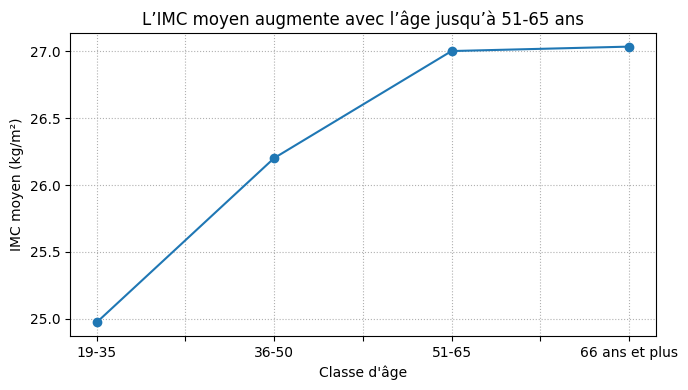

In [26]:
# PARTIE 3 et 4 – Graphiques Matplotlib
# Question 13 – Courbe de l’IMC moyen par classe d’âge
moyennes = df.groupby("classe_age", observed=True)["imc"].mean()
print(moyennes)

plt.figure(figsize=(7, 4))
moyennes.plot(marker="o")
plt.title("L’IMC moyen augmente avec l’âge jusqu’à 51-65 ans")
plt.xlabel("Classe d'âge")
plt.ylabel("IMC moyen (kg/m²)")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()
# Interprétation : L’IMC moyen augmente avec l’âge jusqu’à 51-65 ans, puis se stabilise.

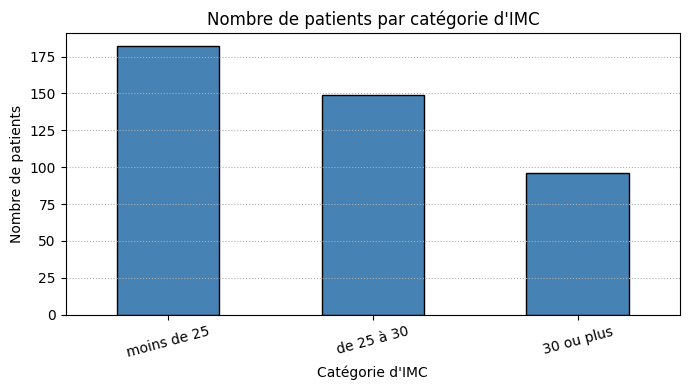

In [25]:
# Question 14 – Diagramme en barres (effectifs IMC)
effectifs = df["categorie_imc"].value_counts(sort=False)

plt.figure(figsize=(7, 4))
effectifs.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Nombre de patients par catégorie d'IMC")
plt.xlabel("Catégorie d'IMC")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

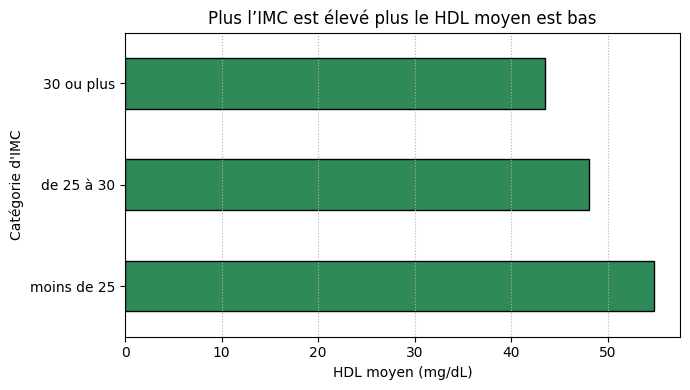

In [28]:
# Question 15 – Barres horizontales (HDL moyen)
hdl_moyen = df.groupby("categorie_imc", observed=True)["hdl"].mean()

plt.figure(figsize=(7, 4))
hdl_moyen.plot(kind="barh", color="seagreen", edgecolor="black")
plt.title("Plus l’IMC est élevé plus le HDL moyen est bas")
plt.xlabel("HDL moyen (mg/dL)")
plt.ylabel("Catégorie d'IMC")
plt.grid(axis="x", linestyle=":")
plt.tight_layout()
plt.show()
#Interprétation :Plus l’IMC est élevé, plus le HDL moyen est bas.

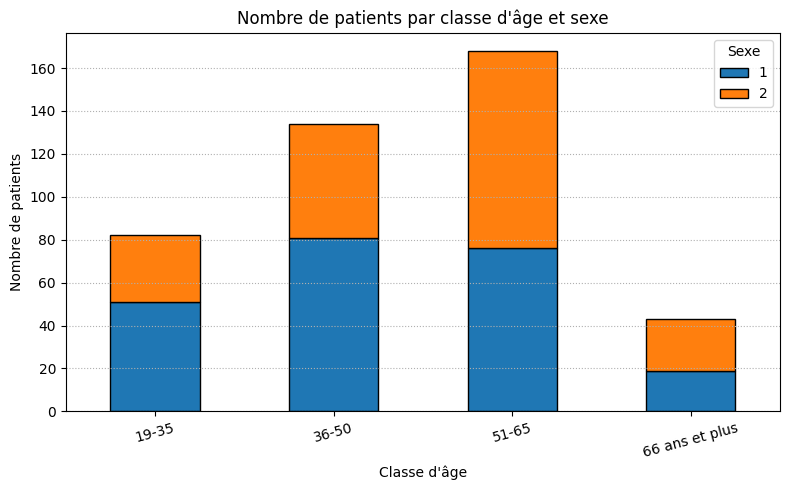

In [29]:
# Question 16 – Barres empilées (âge × sexe)
tableau = pd.crosstab(df["classe_age"], df["sexe"])

tableau.plot(kind="bar", stacked=True, figsize=(8, 5), edgecolor="black")
plt.title("Nombre de patients par classe d'âge et sexe")
plt.xlabel("Classe d'âge")
plt.ylabel("Nombre de patients")
plt.legend(title="Sexe")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

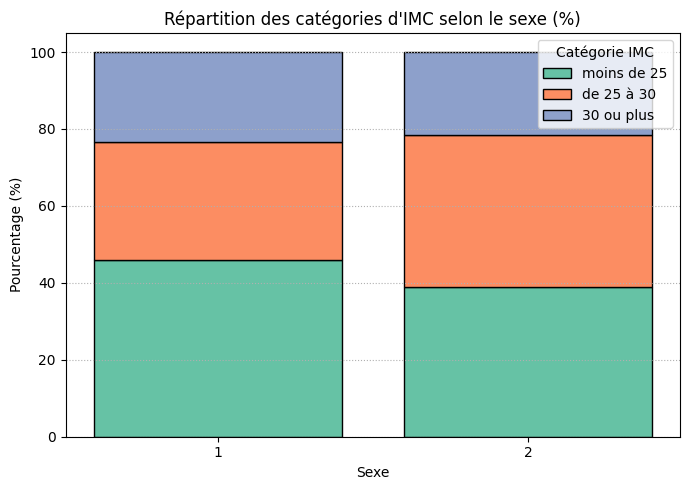

In [30]:
#Question 17 – Barres empilées à 100 %
prop = pd.crosstab(df["sexe"], df["categorie_imc"], normalize="index") * 100

plt.figure(figsize=(7, 5))
bas = np.zeros(len(prop))
couleurs = ["#66c2a5", "#fc8d62", "#8da0cb"]

for i, cat in enumerate(prop.columns):
    plt.bar(prop.index.astype(str), prop[cat], bottom=bas, label=cat, color=couleurs[i], edgecolor="black")
    bas = bas + prop[cat].values

plt.title("Répartition des catégories d'IMC selon le sexe (%)")
plt.xlabel("Sexe")
plt.ylabel("Pourcentage (%)")
plt.legend(title="Catégorie IMC")
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

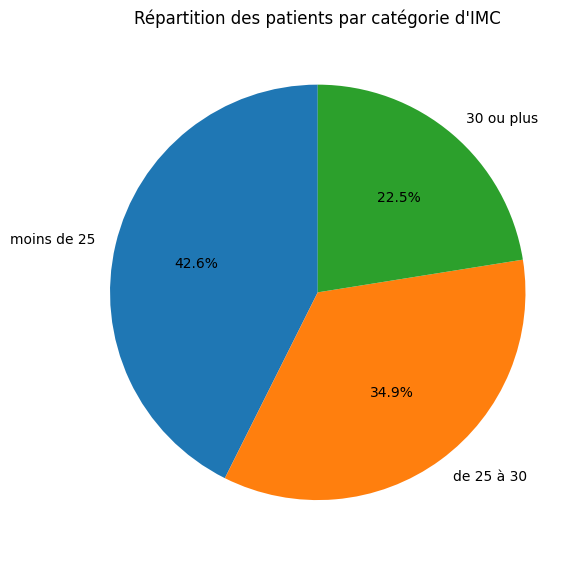

In [31]:
# Question 20 – Diagramme en secteurs
effectifs = df["categorie_imc"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(effectifs, labels=effectifs.index, autopct="%1.1f%%", startangle=90)
plt.title("Répartition des patients par catégorie d'IMC")
plt.tight_layout()
plt.show()

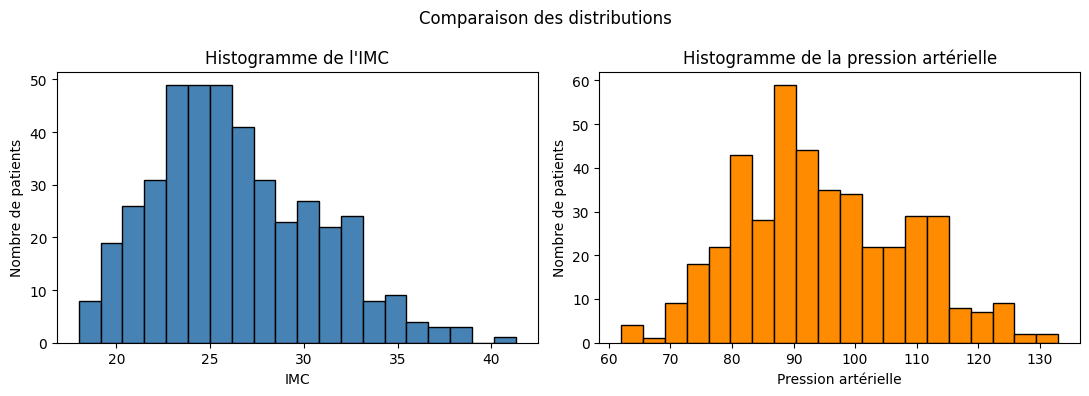

In [32]:
# Question 21 – Deux histogrammes côte à côte
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["imc"], bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("Histogramme de l'IMC")
axes[0].set_xlabel("IMC")
axes[0].set_ylabel("Nombre de patients")

axes[1].hist(df["pa"], bins=20, color="darkorange", edgecolor="black")
axes[1].set_title("Histogramme de la pression artérielle")
axes[1].set_xlabel("Pression artérielle")
axes[1].set_ylabel("Nombre de patients")

fig.suptitle("Comparaison des distributions")
fig.tight_layout()
plt.show()

/tmp/ipykernel_2324/2661238777.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groupes, labels=cats, showmeans=True)


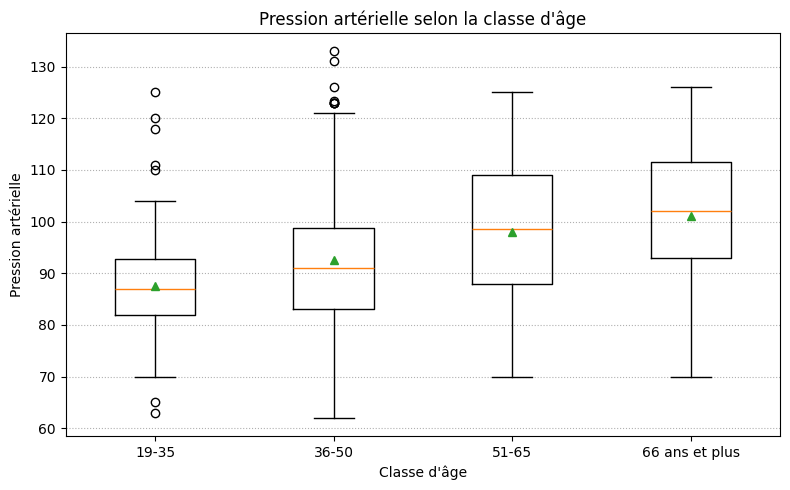

In [33]:
# Question 22 – Boîtes à moustaches (PA selon âge)
cats = df["classe_age"].cat.categories
groupes = [df.loc[df["classe_age"] == c, "pa"] for c in cats]

plt.figure(figsize=(8, 5))
plt.boxplot(groupes, labels=cats, showmeans=True)
plt.title("Pression artérielle selon la classe d'âge")
plt.xlabel("Classe d'âge")
plt.ylabel("Pression artérielle")
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

In [34]:
# PARTIE 5 – Seaborn
# On active un thème plus joli
sns.set_theme(style="whitegrid", font_scale=1.1)

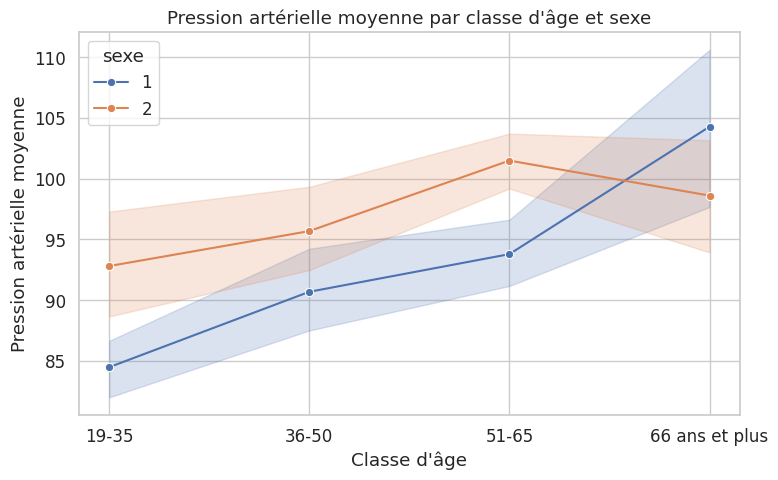

In [35]:
# Question 23 – Courbes avec intervalle de confiance
plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x="classe_age", y="pa", hue="sexe", marker="o")
plt.title("Pression artérielle moyenne par classe d'âge et sexe")
plt.xlabel("Classe d'âge")
plt.ylabel("Pression artérielle moyenne")
plt.tight_layout()
plt.show()

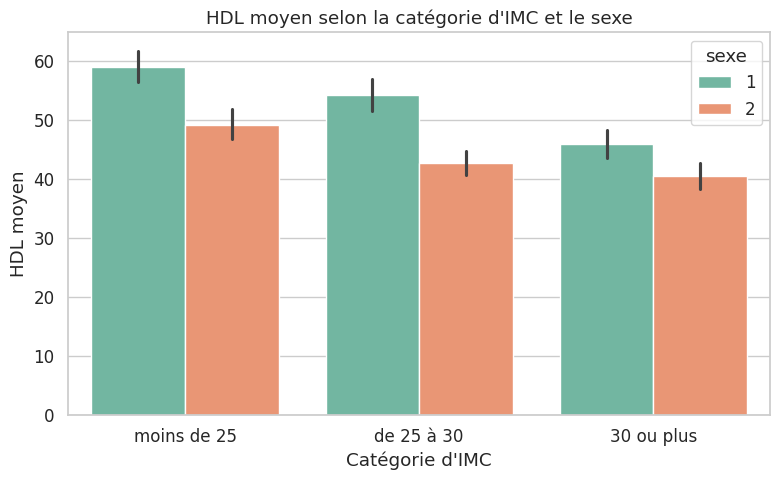

In [36]:
#Question 24 – Barres HDL selon IMC et sexe
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="categorie_imc", y="hdl", hue="sexe", palette="Set2")
plt.title("HDL moyen selon la catégorie d'IMC et le sexe")
plt.xlabel("Catégorie d'IMC")
plt.ylabel("HDL moyen")
plt.tight_layout()
plt.show()

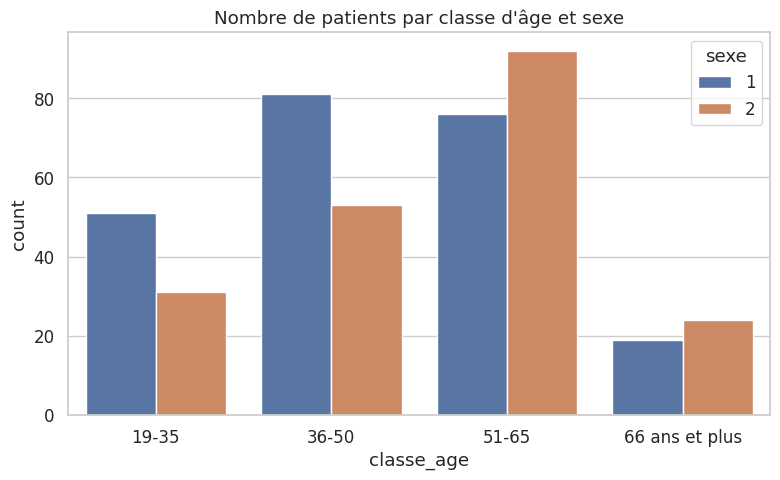

In [37]:
# Question 25 – Countplot
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="classe_age", hue="sexe")
plt.title("Nombre de patients par classe d'âge et sexe")
plt.tight_layout()
plt.show()

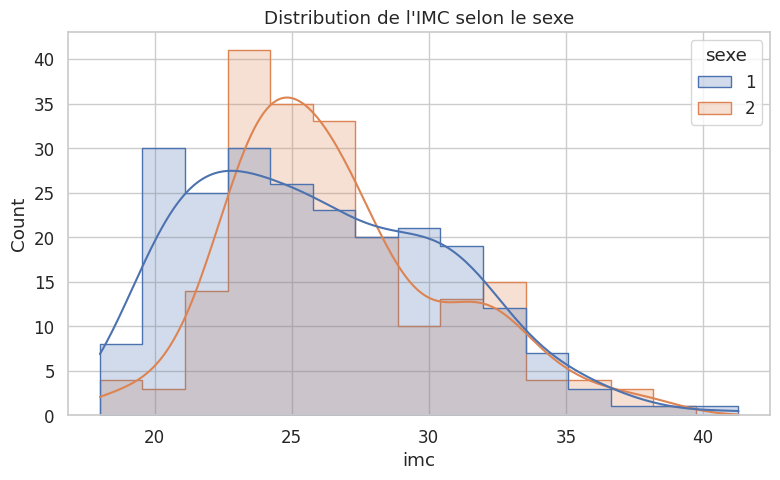

In [38]:
# Question 26 – Histogramme + densité
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="imc", hue="sexe", kde=True, element="step")
plt.title("Distribution de l'IMC selon le sexe")
plt.tight_layout()
plt.show()

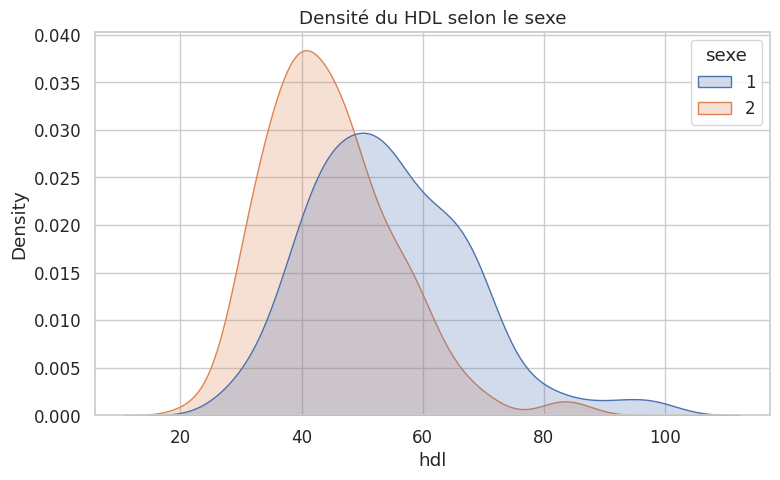

In [39]:
# Question 27 – Densité HDL
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="hdl", hue="sexe", fill=True, common_norm=False)
plt.title("Densité du HDL selon le sexe")
plt.tight_layout()
plt.show()

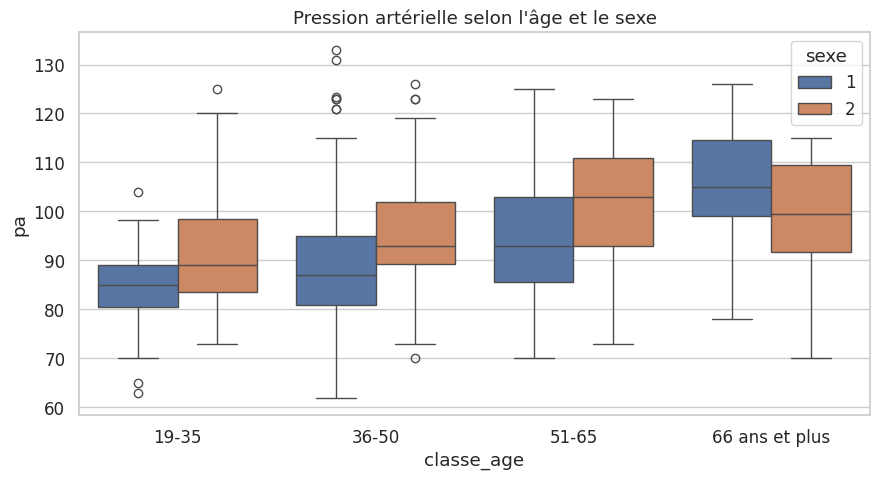

In [40]:
# Question 28 – Boxplot avec hue
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="classe_age", y="pa", hue="sexe")
plt.title("Pression artérielle selon l'âge et le sexe")
plt.tight_layout()
plt.show()

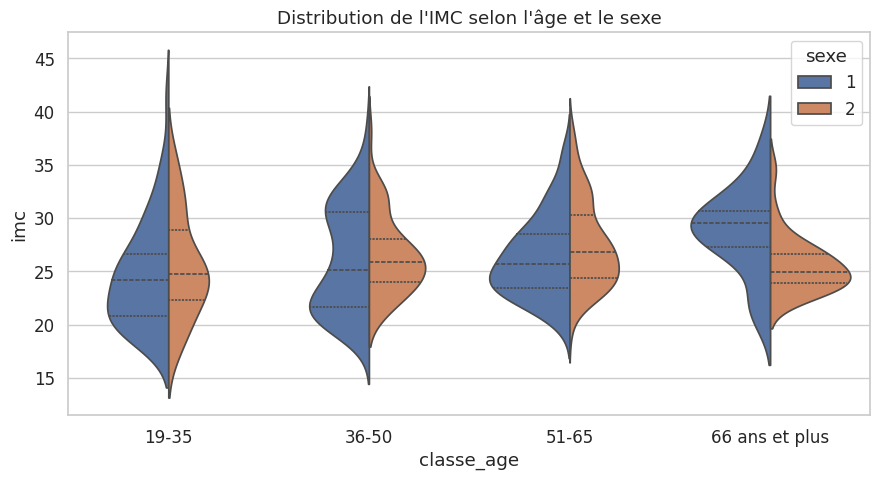

In [41]:
# Question 29 – Violons
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="classe_age", y="imc", hue="sexe", split=True, inner="quartile")
plt.title("Distribution de l'IMC selon l'âge et le sexe")
plt.tight_layout()
plt.show()

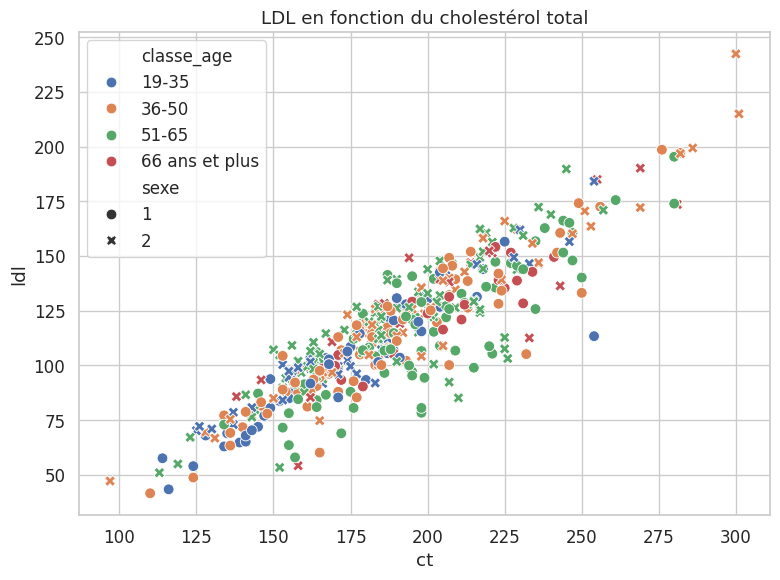

In [42]:
# Question 30 – Scatter avec couleur et forme
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="ct", y="ldl", hue="classe_age", style="sexe", s=60)
plt.title("LDL en fonction du cholestérol total")
plt.tight_layout()
plt.show()

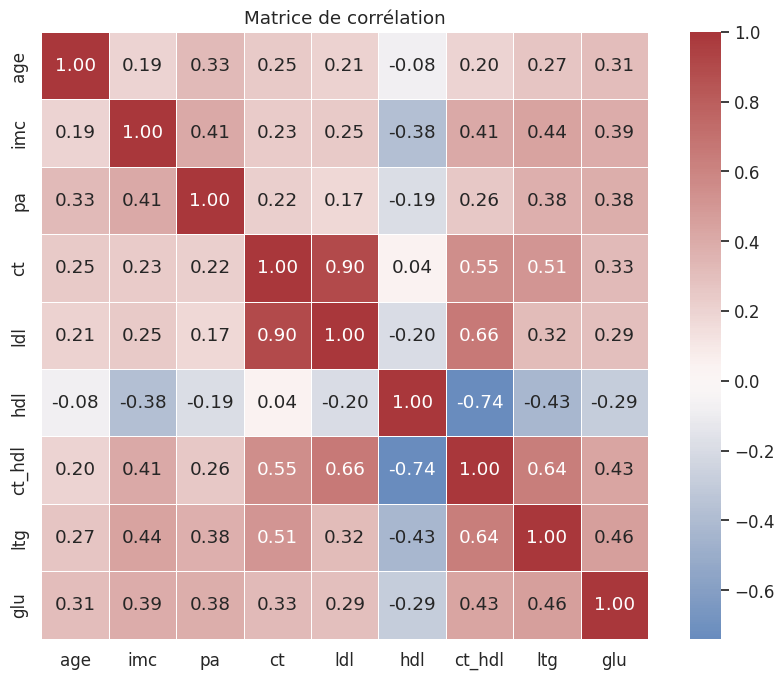

In [43]:
# Question 31 – Heatmap de corrélation
vars_num = ["age", "imc", "pa", "ct", "ldl", "hdl", "ct_hdl", "ltg", "glu"]
corr = df[vars_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, linewidths=0.5)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

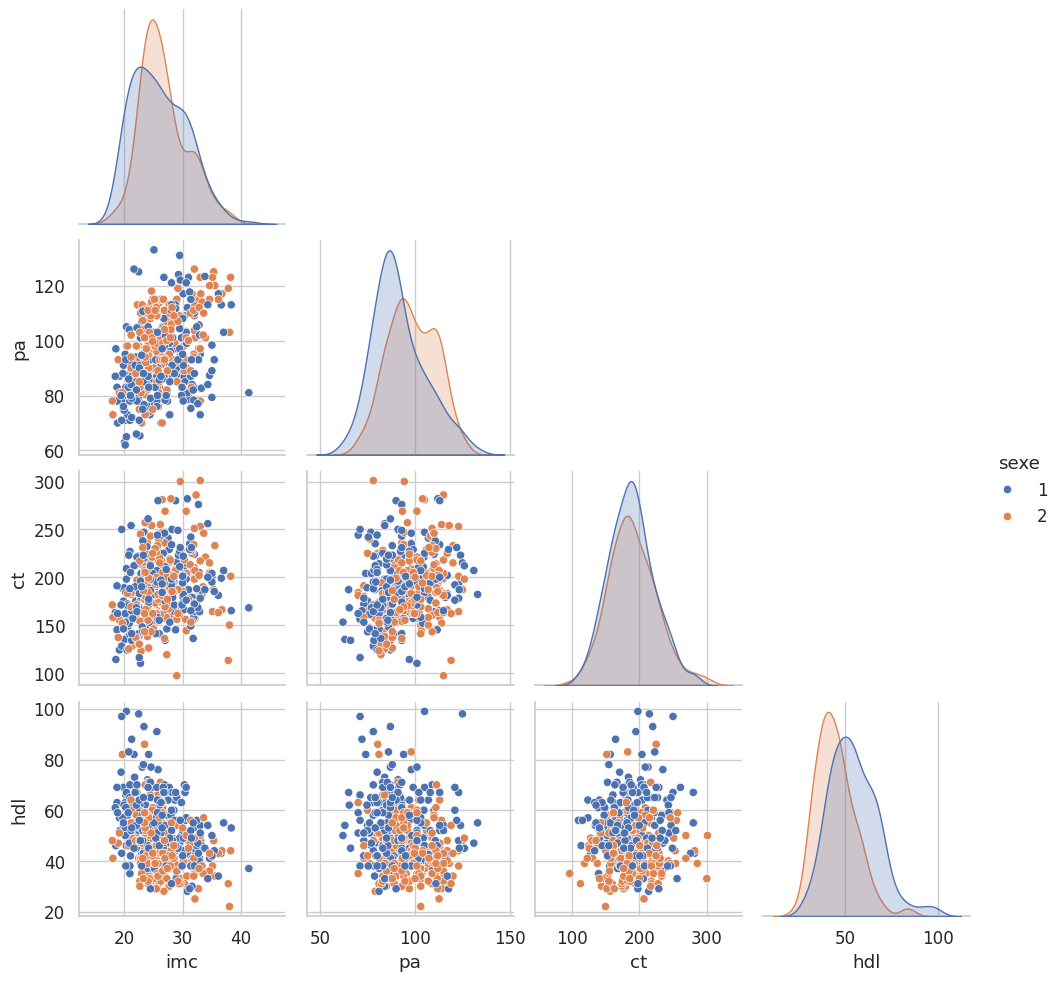

In [44]:
# Question 32 – Pairplot
sns.pairplot(df, vars=["imc", "pa", "ct", "hdl"], hue="sexe", corner=True)
plt.show()

/tmp/ipykernel_2324/434637136.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="sexe", y="imc", ax=axes[1], palette="Set2")


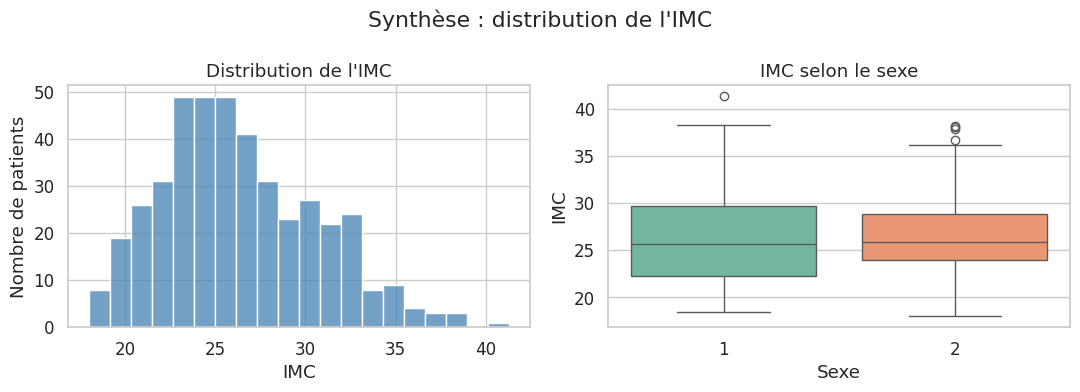

In [45]:
# PARTIE 6 – Figure finale
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=df, x="imc", bins=20, ax=axes[0], color="steelblue")
axes[0].set(title="Distribution de l'IMC", xlabel="IMC", ylabel="Nombre de patients")

sns.boxplot(data=df, x="sexe", y="imc", ax=axes[1], palette="Set2")
axes[1].set(title="IMC selon le sexe", xlabel="Sexe", ylabel="IMC")

fig.suptitle("Synthèse : distribution de l'IMC")
fig.tight_layout()
plt.show()